# 08 CO2減衰と多室保存

単室減衰と、50／100 m³の閉鎖二室間輸送。奈良・東大阪の換気量推定例の基礎。

## 到達目標
単室はc(t)=c0 exp(−Qt/V)。結合二室は同時刻の陰解法。閉鎖系ではΣVcを保存する。濃度単位と発生量単位を合わせる。

## 実行環境
Python 3.10以上とvtsimnx engineが必要です。Colabのlocalhostは手元PCのサーバーを指しません。次の設定セルのAPI URLを到達可能なものに変更します。APIキーは環境変数で渡し、ノートに保存しません。

検証engine commit: `5eeffb2f8012a2fe41bca705450b0dd0a952326d`。入力モデルは実計算確認済ですが、原住宅の年間再現とは範囲が異なります。

## 実行版の使い方
このノートは検証対象のvtsimnx commit 5eeffb2f8012a2fe41bca705450b0dd0a952326d に合わせた代表教材です。上から順に実行します。
Pythonクライアントの導入だけではengineは起動しません。教材17以外は接続可能なengineと、必要に応じてVTSIMNX_API_KEYが必要です。Colabの127.0.0.1は手元PCのengineを指しません。
入力はノート内に含めています。元のDriveパスや測定CSVを別途読む必要はありません。
出力は教材フォルダ内のresults/08/に保存します。詳しい準備は同じフォルダの00_実行ガイド.ipynbを参照してください。


In [1]:
import os, sys, subprocess
# 検証runnerのみ専用環境で導入済みの依存を再利用する。通常はこのセルで導入する。
if os.environ.get("VTSIMNX_TUTORIAL_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip", "setuptools>=68,<81", "wheel"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "vtsimnx @ git+https://github.com/iguchi-lab/vtsimnx@5eeffb2f8012a2fe41bca705450b0dd0a952326d",
        "matplotlib", "japanize-matplotlib"])


In [2]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from IPython.display import display
import vtsimnx as vt

# ローカルJupyterでは、ノートブックと同じフォルダを作業フォルダにする。
DATA_DIR = Path(os.environ.get("VTSIMNX_TUTORIAL_DATA", ".")).expanduser().resolve()
BASE_URL = os.environ.get("VTSIMNX_API_URL", "http://127.0.0.1:8000")
API_KEY = os.environ.get("VTSIMNX_API_KEY")
OUTPUT = DATA_DIR / "results" / "08"
OUTPUT.mkdir(parents=True, exist_ok=True)


## 入力を読む
次の辞書はvtsimnxのネイティブ形式です。風量はm³/s、熱量はW、熱容量はJ/Kです。

In [3]:
configs = {'08_co2_decay': {'builder': {},
                  'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                           'end': '2026-01-01T00:59:00',
                                           'length': 60,
                                           'timestep': 60}},
                  'nodes': [{'key': 'outside', 't': 20, 'c': 0},
                            {'key': 'room', 't': 20, 'c': 1000, 'calc_c': True, 'v': 50, 'beta': 0}],
                  'ventilation_branches': [{'key': 'outside->room',
                                            'source': 'outside',
                                            'target': 'room',
                                            'vol': 0.013888888888888888},
                                           {'key': 'room->outside',
                                            'source': 'room',
                                            'target': 'outside',
                                            'vol': 0.013888888888888888}],
                  'thermal_branches': []},
 '08_co2_two_rooms': {'builder': {},
                      'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                               'end': '2026-01-01T00:59:00',
                                               'length': 60,
                                               'timestep': 60}},
                      'nodes': [{'key': 'outside', 't': 20, 'c': 0},
                                {'key': 'room', 't': 20, 'c': 1000, 'calc_c': True, 'v': 50, 'beta': 0},
                                {'key': 'room2', 't': 20, 'c': 0, 'calc_c': True, 'v': 100}],
                      'ventilation_branches': [{'key': 'room->room2',
                                                'source': 'room',
                                                'target': 'room2',
                                                'vol': 0.013888888888888888},
                                               {'key': 'room2->room',
                                                'source': 'room2',
                                                'target': 'room',
                                                'vol': 0.013888888888888888}],
                      'thermal_branches': []}}


## 実行と結果の取得
計算ごとの要求JSONを保存し、必要な系列をDataFrameとして取得します。

In [4]:
results = {}
for name, config in configs.items():
    results[name] = vt.run_calc(BASE_URL, config, api_key=API_KEY,
        as_result=True, raise_on_error=True, timeout=1800, request_output_path=OUTPUT / (name + "_request.json"))
    print(name, results[name].artifact_dir)


08_co2_decay artifacts.1794699406079.output.f05190624a644e29addafcc35fbb83d2


08_co2_two_rooms artifacts.1794699407102.output.e71ff0a4f4214bdc87f2b18c8eafc5bd


08_co2_decay


,room
time,
2026-01-01 00:00:00,983.471436
2026-01-01 00:01:00,967.216125
2026-01-01 00:02:00,951.229431
2026-01-01 00:03:00,935.506958
2026-01-01 00:04:00,920.044434


08_co2_two_rooms


,room,room2
time,,
2026-01-01 00:00:00,983.739807,8.130081
2026-01-01 00:01:00,967.876282,16.061869
2026-01-01 00:02:00,952.399597,23.800196
2026-01-01 00:03:00,937.300415,31.349785
2026-01-01 00:04:00,922.569519,38.715237


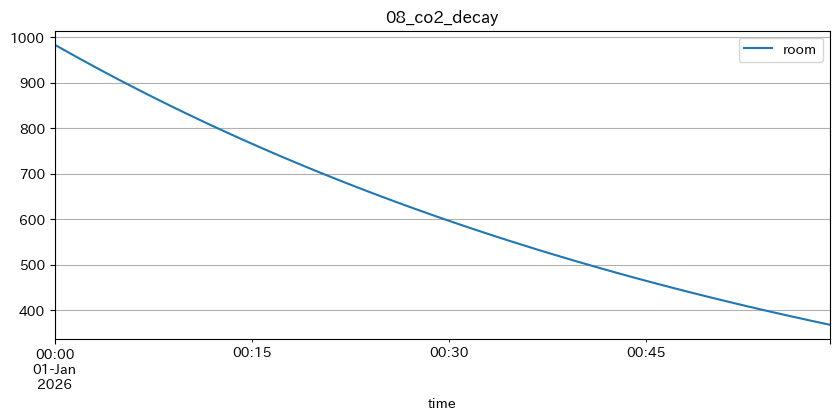

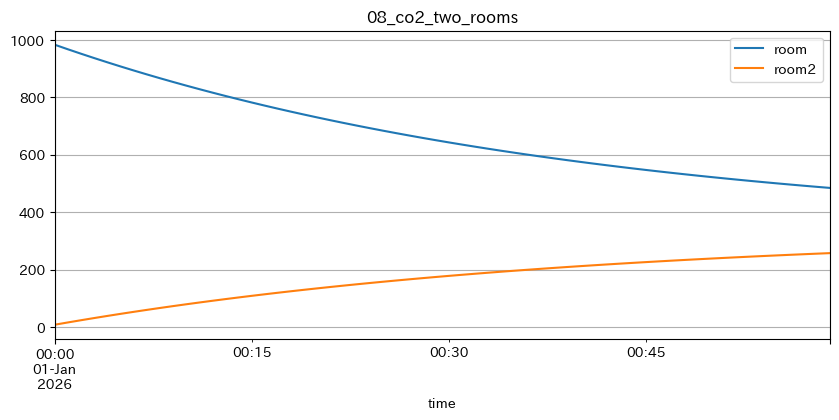

In [5]:
frames = {name: result.get_series_df('concentration_c', raise_on_error=True) for name, result in results.items()}
for name, frame in frames.items():
    print(name)
    display(frame.head())
    frame.to_csv(OUTPUT / (name + "_concentration_c.csv"), encoding="utf-8-sig")
    frame.plot(title=name, figsize=(10, 4), grid=True)


In [6]:
observed = frames["08_co2_decay"]["room"].to_numpy()
expected = 1000*np.exp(-np.arange(1,61)/60)
assert np.max(np.abs(observed-expected)) < 0.01
print("単室の解析解と一致")


単室の解析解と一致


## 確認・発展
時間刻みを1/2にし、保存性と過渡精度を分けて評価する。

保存された時刻の値は当該ステップ更新後の値です。初期値との比較ではこの差に注意します。

## 原典との対応
- S026 240108_東大阪_vtsim.ipynb
- S073 230927_枚方_vtsim.ipynb
- S074 230927_枚方_vtsim.ipynb のコピー
- S076 231127_枚方_vtsim.ipynb
- S077 240123_枚方_vtsim.ipynb
- S078 240207_枚方_vtsim.ipynb
- S082 250106_Nara_CO2_1F2F同時.ipynb
- S084 250107_Nara_CO2_1F2F別_制限なし.ipynb
- S085 250107_Nara_CO2_1F2F別_学生共有.ipynb
- S086 250107_r2_Nara_CO2_1F2F別_制限なし.ipynb
- S087 CO2.ipynb
- S088 CO2.ipynb のコピー のコピー

S番号は原典調査時の識別子です。原典の完全な台帳は管理者のDrive整理資料に保管しています。